In [1]:
# PHASE 1 – INSTALLATION DES BIBLIOTHÈQUES
#
# Objectif :
# Installer les bibliothèques nécessaires pour :
# - créer un environnement de jeu Atari avec Gymnasium/ALE ;
# - entraîner un agent DQN avec Stable-Baselines3 ;
# - enregistrer des vidéos de l'agent ;
# - tracer les courbes d'apprentissage.

!apt-get update -qq
!apt-get install -y -qq ffmpeg

!pip install -q "stable-baselines3[extra]" \
    "gymnasium[atari,accept-rom-license]" \
    "ale-py" \
    "autorom[accept-rom-license]" \
    "moviepy"

# Téléchargement/installation des ROMs Atari.
!AutoROM --accept-license


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 434.7/434.7 kB 13.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 952.1/952.1 kB 46.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 97.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 187.5/187.5 kB 18.4 MB/s eta 0:00:00
AutoROM will download the Atari 2600 ROMs.
They will be installed to:
	/usr/local/lib/python3.12/dist-packages/AutoROM/roms

Existing ROMs will be overwritten.


In [2]:
# PHASE 2 – IMPORTATION DES BIBLIOTHÈQUES
#
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import HTML, display
from base64 import b64encode

import gymnasium as gym
import ale_py

# Cette ligne permet d'enregistrer les environnements Atari dans Gymnasium.
# Elle évite souvent l'erreur : Namespace ALE not found.
gym.register_envs(ale_py)

from stable_baselines3 import DQN

from stable_baselines3.common.env_util import make_atari_env
from stable_baselines3.common.vec_env import VecFrameStack, VecVideoRecorder
from stable_baselines3.common.evaluation import evaluate_policy
from stable_baselines3.common.callbacks import EvalCallback, CheckpointCallback
from stable_baselines3.common.results_plotter import load_results, ts2xy, X_TIMESTEPS


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## II.1 — Installation et importation des bibliothèques

**Modifications par rapport à Pong :** aucune modification dans cette phase. Les bibliothèques utilisées sont exactement les mêmes : `gymnasium`, `ale-py`, `stable-baselines3`, `moviepy` et `ffmpeg`.

**Pourquoi ces bibliothèques sont-elles suffisantes pour un nouveau jeu Atari ?**

La bibliothèque `ale-py` contient les ROMs de plus de 50 jeux Atari. Changer de jeu revient simplement à modifier l'identifiant d'environnement (`ENV_ID`). Toute la logique de pipeline — entraînement, évaluation, enregistrement vidéo — reste identique car elle est agnostique au jeu ciblé.

**Jeu choisi : SpaceInvaders (`ALE/SpaceInvaders-v5`)**

Space Invaders est un jeu de tir classique où l'agent contrôle un canon au bas de l'écran et doit éliminer des vagues d'envahisseurs qui descendent progressivement. Il présente des caractéristiques intéressantes :
- un espace d'actions plus riche que Pong (6 actions) ;
- une récompense positive (à chaque ennemi touché) plutôt que binaire comme dans Pong ;
- un environnement avec plusieurs ennemis simultanés, ce qui complexifie la politique optimale.


In [ ]:
# PHASE 3 – PARAMÈTRES GÉNÉRAUX DE L'EXPÉRIENCE

# MODIFICATION 1 : Jeu choisi — Space Invaders au lieu de Pong.
# L'agent contrôle un canon et doit détruire les envahisseurs tout en esquivant leurs tirs.
ENV_ID = "ALE/SpaceInvaders-v5"

# Nombre total de steps d'entraînement.
# Space Invaders nécessite plus de temps pour apprendre une politique utile.
TOTAL_TIMESTEPS = 500_000

# Nombre d'environnements parallèles.
N_ENVS = 1

# Nombre de frames empilées.
# Comme pour Pong, 4 frames permettent de percevoir le mouvement des envahisseurs
# et la direction des projectiles.
N_STACK = 4

SEED = 42

#  MODIFICATION 2 : Dossiers renommés pour ce nouveau jeu.
BASE_DIR = "./dqn_spaceinvaders_demo"
LOG_DIR = os.path.join(BASE_DIR, "logs")
EVAL_LOG_DIR = os.path.join(BASE_DIR, "eval_logs")
MODEL_DIR = os.path.join(BASE_DIR, "models")
BEST_MODEL_DIR = os.path.join(BASE_DIR, "best_model")
VIDEO_DIR_RANDOM = os.path.join(BASE_DIR, "videos_random")
VIDEO_DIR_TRAINED = os.path.join(BASE_DIR, "videos_trained")
TENSORBOARD_DIR = os.path.join(BASE_DIR, "tensorboard")

for path in [LOG_DIR, EVAL_LOG_DIR, MODEL_DIR, BEST_MODEL_DIR,
             VIDEO_DIR_RANDOM, VIDEO_DIR_TRAINED, TENSORBOARD_DIR]:
    os.makedirs(path, exist_ok=True)


## II.2 — Définition des paramètres généraux de l'expérience

**Éléments modifiés par rapport à Pong et justification :**

- `ENV_ID` → `"ALE/SpaceInvaders-v5"` : changement du jeu cible. Space Invaders propose une dynamique très différente de Pong — récompenses positives, plusieurs ennemis, gestion de vies.
- `BASE_DIR` → `"./dqn_spaceinvaders_demo"` : dossier dédié pour ne pas écraser les résultats de la Partie I.
- `N_STACK = 4` : inchangé. L'empilement de 4 frames reste nécessaire pour percevoir les trajectoires des projectiles et le mouvement des envahisseurs.
- `SEED = 42` : inchangé pour permettre une comparaison équitable.
- `TOTAL_TIMESTEPS = 500_000` : identique à la Partie I. Pour Space Invaders, une politique clairement améliorée nécessite généralement 1 à 3 millions de steps ; on reste ici dans un cadre de démonstration raisonnable.

**Pourquoi Space Invaders est-il un environnement plus complexe que Pong ?**

Dans Pong, l'agent ne gère qu'une balle et une raquette. Dans Space Invaders, il doit simultanément cibler plusieurs ennemis, esquiver des tirs ennemis, et gérer un nombre de vies limité. La récompense est également structurée différemment : elle est positive et augmente avec le rang des ennemis détruits, ce qui encourage des comportements plus variés.


Type de l'observation : <class 'numpy.ndarray'>
Shape de l'observation : (210, 160, 3)
Type des pixels : uint8

Espace d'actions : Discrete(6)
Nombre d'actions possibles : 6
Signification des actions : ['NOOP', 'FIRE', 'RIGHT', 'LEFT', 'RIGHTFIRE', 'LEFTFIRE']


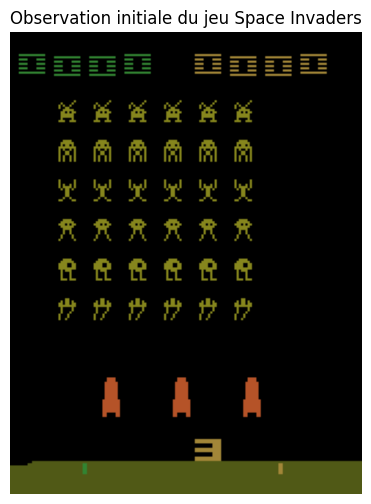

In [ ]:
# PHASE 4 – EXPLORATION DE L'ENVIRONNEMENT
#
# MODIFICATION : ENV_ID est maintenant ALE/SpaceInvaders-v5.
# On inspecte l'espace d'observation et d'actions spécifiques à ce jeu.
raw_env = gym.make(
    ENV_ID,
    render_mode="rgb_array",
    full_action_space=False
)
obs, info = raw_env.reset(seed=SEED)

print("Type de l'observation :", type(obs))
print("Shape de l'observation :", obs.shape)
print("Type des pixels :", obs.dtype)
print("\nEspace d'actions :", raw_env.action_space)
print("Nombre d'actions possibles :", raw_env.action_space.n)
print("Signification des actions :", raw_env.unwrapped.get_action_meanings())

# Affichage d'une image initiale du jeu.
frame = raw_env.render()
plt.figure(figsize=(5, 6))
plt.imshow(frame)
plt.axis("off")
plt.title("Observation initiale du jeu Space Invaders")
plt.show()
raw_env.close()


## II.3 — Exploration de l'environnement Space Invaders

**Q1 — Que représente l'état observé par l'agent dans Space Invaders ?**

L'observation est une image RGB de taille (210, 160, 3) en pixels uint8, identique à Pong en termes de dimensions. Elle représente une capture d'écran du jeu : les envahisseurs, le canon du joueur, les projectiles ennemis, les boucliers et le score. C'est l'information brute que l'agent utilise pour décider de son action.

**Q2 — En quoi cet espace d'actions diffère-t-il de celui de Pong ?**

Space Invaders possède 6 actions : `NOOP`, `FIRE`, `RIGHT`, `LEFT`, `RIGHTFIRE`, `LEFTFIRE`. C'est le même nombre d'actions que Pong, mais leur sémantique est différente : dans Space Invaders, `FIRE` tire un projectile vers le haut, et les actions de déplacement servent à repositionner le canon. L'agent doit donc apprendre à coordonner déplacement et tir, ce qui est plus complexe que simplement déplacer une raquette.

**Q3 — Pourquoi `CnnPolicy` reste-t-elle adaptée ?**

Comme pour Pong, l'entrée est une image pixel. Le CNN extrait automatiquement les caractéristiques visuelles pertinentes : positions des envahisseurs, trajectoires des projectiles, état des boucliers. Ces caractéristiques sont ensuite utilisées pour estimer les valeurs Q de chaque action.

**Q4 — Quelle différence fondamentale existe-t-il dans la structure de la récompense par rapport à Pong ?**

Dans Pong, la récompense est binaire : +1 quand l'adversaire rate, −1 quand le joueur rate. Dans Space Invaders, la récompense est positive et variable : chaque ennemi détruit rapporte des points (5, 10 ou 15 selon le rang). Il n'y a pas de récompense négative directe (sauf la fin de partie), ce qui change profondément la dynamique d'apprentissage : l'agent cherche à maximiser le score plutôt qu'à éviter la défaite.


In [5]:
# PHASE 5 – CRÉATION DES ENVIRONNEMENTS D'ENTRAÎNEMENT ET D'ÉVALUATION
#
# Aucune modification de structure par rapport à Pong.
# ENV_ID pointe maintenant vers Space Invaders.
train_env = make_atari_env(
    ENV_ID,
    n_envs=N_ENVS,
    seed=SEED,
    monitor_dir=LOG_DIR,
    env_kwargs={
        "render_mode": "rgb_array",
        "full_action_space": False
    }
)

# Empilement de 4 frames successives.
# Indispensable pour percevoir la direction et vitesse des projectiles ennemis.
train_env = VecFrameStack(train_env, n_stack=N_STACK)

# Environnement d'évaluation séparé avec un seed différent.
eval_env = make_atari_env(
    ENV_ID,
    n_envs=1,
    seed=SEED + 100,
    monitor_dir=EVAL_LOG_DIR,
    env_kwargs={
        "render_mode": "rgb_array",
        "full_action_space": False
    }
)
eval_env = VecFrameStack(eval_env, n_stack=N_STACK)

print("Environnement d'entraînement prêt.")
print("Environnement d'évaluation prêt.")


Environnement d'entraînement prêt.
Environnement d'évaluation prêt.


## II.4 — Création des environnements d'entraînement et d'évaluation

**Éléments modifiés par rapport à Pong :** uniquement `ENV_ID`. La structure complète (Monitor, VecFrameStack, seed séparé pour l'évaluation) est conservée à l'identique, car ces choix de conception sont justifiés indépendamment du jeu.

**Pourquoi l'empilement de frames est-il particulièrement important pour Space Invaders ?**

Dans Space Invaders, les projectiles ennemis se déplacent rapidement vers le bas. Une seule image ne permet pas de distinguer un projectile statique d'un projectile en mouvement. En empilant 4 frames, l'agent peut percevoir la trajectoire descente des tirs, ce qui est essentiel pour les esquiver. De même, la formation des envahisseurs se déplace latéralement, et seul l'empilement permet d'en percevoir le sens et la vitesse.

**Pourquoi séparer environnement d'entraînement et d'évaluation ?**

L'environnement d'entraînement est bruité par l'exploration (actions aléatoires fréquentes), ce qui biaise les statistiques d'épisode. L'environnement d'évaluation utilise une politique déterministe sur des épisodes complets, ce qui donne une mesure fidèle de la vraie performance de l'agent, sans interférence de l'exploration.


In [6]:
# PHASE 6A – FONCTION POUR AFFICHER UNE VIDÉO DANS COLAB

def display_video(video_path, width=600):
    """
    Affiche une vidéo MP4 directement dans Google Colab.
    """
    mp4 = open(video_path, "rb").read()
    data_url = "data:video/mp4;base64," + b64encode(mp4).decode()
    display(HTML(f"""\
    <video width="{width}" controls>
    <source src="{data_url}" type="video/mp4">
    </video>"""))

def get_latest_video(video_dir):
    """
    Récupère la dernière vidéo MP4 générée dans un dossier.
    """
    videos = glob.glob(os.path.join(video_dir, "*mp4"))
    if len(videos) == 0:
        raise FileNotFoundError("Aucune vidéo MP4 trouvée.")
    return sorted(videos, key=os.path.getmtime)[-1]


In [7]:
# PHASE 6 – ENREGISTRER UNE VIDÉO D'UN AGENT

def record_agent_video(model=None, video_folder=VIDEO_DIR_RANDOM,
                       prefix="agent", n_steps=2000, seed=123):
    """
    Enregistre une vidéo de l'agent.

    Si model=None :
        l'agent joue aléatoirement.

    Si model contient un modèle DQN :
        l'agent utilise la politique apprise.
    """
    os.makedirs(video_folder, exist_ok=True)

    video_env = make_atari_env(
        ENV_ID,
        n_envs=1,
        seed=seed,
        env_kwargs={
            "render_mode": "rgb_array",
            "full_action_space": False
        }
    )
    video_env = VecFrameStack(video_env, n_stack=N_STACK)
    video_env = VecVideoRecorder(
        video_env,
        video_folder,
        record_video_trigger=lambda step: step == 0,
        video_length=n_steps,
        name_prefix=prefix
    )

    obs = video_env.reset()
    total_reward = 0

    for step in range(n_steps):
        if model is None:
            action = np.array([video_env.action_space.sample()])
        else:
            action, _ = model.predict(obs, deterministic=True)

        obs, rewards, dones, infos = video_env.step(action)
        total_reward += float(rewards[0])

        if dones[0]:
            break

    video_env.close()

    latest_video = get_latest_video(video_folder)
    print("Récompense totale de l'épisode filmé :", total_reward)
    print("Vidéo enregistrée :", latest_video)
    display_video(latest_video)


In [ ]:
# Vidéo avant apprentissage : agent aléatoire.
# MODIFICATION : prefix renommé pour Space Invaders.
record_agent_video(
    model=None,
    video_folder=VIDEO_DIR_RANDOM,
    prefix="random-agent-spaceinvaders",
    n_steps=2000,
    seed=SEED
)


/usr/local/lib/python3.12/dist-packages/moviepy/config_defaults.py:47: SyntaxWarning: invalid escape sequence '\P'
  IMAGEMAGICK_BINARY = r"C:\Program Files\ImageMagick-6.8.8-Q16\magick.exe"


Moviepy - Building video /content/dqn_spaceinvaders_demo/videos_random/random-agent-spaceinvaders-step-0-to-step-2000.mp4.
Moviepy - Writing video /content/dqn_spaceinvaders_demo/videos_random/random-agent-spaceinvaders-step-0-to-step-2000.mp4



/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
                                                             

Moviepy - Done !
Moviepy - video ready /content/dqn_spaceinvaders_demo/videos_random/random-agent-spaceinvaders-step-0-to-step-2000.mp4
Récompense totale de l'épisode filmé : 0.0
Vidéo enregistrée : ./dqn_spaceinvaders_demo/videos_random/random-agent-spaceinvaders-step-0-to-step-2000.mp4


## II.5 — Vidéo de l'agent aléatoire

**Q1 — Pourquoi est-il important d'observer l'agent avant entraînement ?**

L'agent aléatoire sert de ligne de base (baseline). Il nous permet de quantifier exactement le point de départ avant tout apprentissage. Sans cette référence, il est impossible d'évaluer si l'entraînement a réellement amélioré la politique ou si les scores observés correspondent simplement à un comportement aléatoire.

**Q2 — Quel comportement remarquez-vous dans la vidéo de l'agent aléatoire ?**

L'agent aléatoire tire dans toutes les directions sans stratégie, se déplace de façon erratique et ne cherche pas à esquiver les tirs ennemis. Il marque parfois quelques points par chance (lorsqu'un tir aléatoire touche un envahisseur), mais perd rapidement toutes ses vies. Le score obtenu est généralement très bas (typiquement 0 à 150 points), très loin du score optimal d'un joueur humain (2 000 à 5 000 points).

**Différence majeure avec Pong :** dans Pong, l'agent aléatoire obtenait une récompense de −21 (défaite maximale). Dans Space Invaders, l'agent aléatoire peut quand même marquer quelques points positifs par chance, ce qui illustre la différence de structure des récompenses entre les deux jeux.


In [ ]:
# ============================================================
# PHASE 7 – CRÉATION DU MODÈLE DQN (Adapté pour Space Invaders)
#
# Modifications par rapport à la configuration Pong (Partie I) :
#   1. learning_rate : 5e-5 (identique — bon compromis stabilité/convergence)
#   2. buffer_size augmenté : 100_000 → 150_000
#      Space Invaders a des épisodes plus longs et plus variés ;
#      un buffer plus grand améliore la diversité des expériences rejouées.
#   3. learning_starts augmenté : 50_000 → 60_000
#      L'environnement étant plus complexe, plus d'exploration initiale
#      permet de collecter des expériences plus diversifiées avant d'apprendre.
#   4. batch_size : 64 (inchangé — bonne stabilité des gradients)
#   5. target_update_interval augmenté : 1_000 → 2_000
#      Space Invaders a des dynamiques plus longues ; un réseau cible
#      mis à jour moins fréquemment réduit les oscillations.
#   6. exploration_fraction augmenté : 0.25 → 0.30
#      30% des steps dédiés à l'exploration pour mieux couvrir
#      les situations variées de Space Invaders (différentes formations,
#      positions du canon, présence ou non de boucliers).
#   7. exploration_final_eps : 0.05 (identique)
# ============================================================

model = DQN(
    policy="CnnPolicy",
    env=train_env,
    learning_rate=5e-5,
    buffer_size=150_000,            # Augmenté : épisodes plus longs et variés
    learning_starts=60_000,         # Augmenté : plus d'exploration initiale
    batch_size=64,
    gamma=0.99,
    train_freq=4,
    gradient_steps=1,
    target_update_interval=2_000,   # Augmenté : stabilité accrue
    exploration_initial_eps=1.0,
    exploration_final_eps=0.05,
    exploration_fraction=0.30,      # Augmenté : couverture plus large
    tensorboard_log=TENSORBOARD_DIR,
    verbose=1,
    seed=SEED,
    device="auto"
)

print("=" * 50)
print("POLITIQUE DU MODÈLE :")
print(model.policy)
print("=" * 50)


Using cuda device
Wrapping the env in a VecTransposeImage.
POLITIQUE DU MODÈLE :
CnnPolicy(
  (q_net): QNetwork(
    (features_extractor): NatureCNN(
      (cnn): Sequential(
        (0): Conv2d(4, 32, kernel_size=(8, 8), stride=(4, 4))
        (1): ReLU()
        (2): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2))
        (3): ReLU()
        (4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
        (5): ReLU()
        (6): Flatten(start_dim=1, end_dim=-1)
      )
      (linear): Sequential(
        (0): Linear(in_features=3136, out_features=512, bias=True)
        (1): ReLU()
      )
    )
    (q_net): Sequential(
      (0): Linear(in_features=512, out_features=6, bias=True)
    )
  )
  (q_net_target): QNetwork(
    (features_extractor): NatureCNN(
      (cnn): Sequential(
        (0): Conv2d(4, 32, kernel_size=(8, 8), stride=(4, 4))
        (1): ReLU()
        (2): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2))
        (3): ReLU()
        (4): Conv2d(64, 64, kernel_size=(3

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## II.6 — Création du modèle DQN

**Q1 — Pourquoi le DQN utilise-t-il un réseau de neurones au lieu d'une Q-table ?**

L'espace d'états de Space Invaders (comme celui de Pong) est une image de 210×160×3 pixels, ce qui génère un espace d'états combinatoire gigantesque, impossible à représenter sous forme de table. Un réseau de neurones approxime la fonction Q sans avoir à énumérer tous les états possibles.

**Q2 — Que représente la sortie du réseau DQN ?**

La sortie est un vecteur de 6 valeurs Q, une par action possible. Chaque valeur estime la récompense cumulée espérée si l'agent se trouve dans l'état courant et choisit cette action, puis suit la politique optimale pour le reste de l'épisode.

**Q3 — Quel est le rôle du replay buffer ?**

Le replay buffer stocke les transitions (état, action, récompense, état suivant, terminé) pour permettre l'apprentissage à partir d'expériences passées. Il brise les corrélations temporelles entre les observations consécutives, ce qui rend l'apprentissage plus stable. Dans Space Invaders, un buffer plus grand (150 000) est justifié par la plus grande diversité des situations de jeu.

**Q4 — Quelle est la différence entre le réseau principal et le réseau cible ?**

Le réseau principal est mis à jour à chaque pas de gradient. Le réseau cible est une copie figée du réseau principal, mis à jour périodiquement (tous les `target_update_interval` steps). Cette séparation stabilise l'apprentissage en évitant que la cible d'apprentissage change aussi vite que le réseau qui apprend.

**Q5 — Pourquoi `target_update_interval` est-il augmenté à 2 000 pour Space Invaders ?**

Space Invaders a des épisodes plus longs et une dynamique plus complexe. En mettant à jour le réseau cible moins fréquemment, on lui donne plus de stabilité, ce qui réduit les oscillations dans l'estimation des valeurs Q pendant les phases complexes du jeu (vague d'envahisseurs rapide, gestion des boucliers).

**Q6 — Quelle fonction de perte est utilisée par le DQN ?**

Le DQN utilise la perte de Huber (smooth L1) pour comparer la valeur Q prédite par le réseau principal et la cible de Bellman calculée via le réseau cible. Cette fonction est plus robuste aux erreurs importantes que la MSE, ce qui est utile dans des environnements avec des récompenses très variables comme Space Invaders.

**Q7 — Pourquoi cette fonction de perte n'est-elle pas configurée explicitement dans le code avec Stable-Baselines3 ?**

Stable-Baselines3 configure automatiquement la perte de Huber pour DQN. Ce choix est codé en dur dans l'implémentation, car il est reconnu comme le meilleur choix par défaut pour les environnements Atari. Il n'est pas nécessaire de le spécifier manuellement.


In [ ]:
# PHASE 8 – CALLBACKS D'ÉVALUATION ET DE SAUVEGARDE
#
# MODIFICATION : name_prefix renommé pour Space Invaders.
# La structure des callbacks reste identique à celle de la Partie I.

eval_callback = EvalCallback(
    eval_env,
    best_model_save_path=BEST_MODEL_DIR,
    log_path=EVAL_LOG_DIR,
    eval_freq=20_000,
    n_eval_episodes=5,
    deterministic=True,
    render=False,
    verbose=1
)

checkpoint_callback = CheckpointCallback(
    save_freq=50_000,
    save_path=MODEL_DIR,
    name_prefix="dqn_spaceinvaders_checkpoint"  # ✅ Renommé
)

callbacks = [eval_callback, checkpoint_callback]


## II.7 — Définition des callbacks

**Éléments modifiés par rapport à Pong :** uniquement le `name_prefix` du `CheckpointCallback` (renommé en `dqn_spaceinvaders_checkpoint`). Toute la logique est identique.

**Q1 — À quoi sert `EvalCallback` ?**

`EvalCallback` évalue périodiquement l'agent sur un environnement séparé (toutes les `eval_freq` steps) et sauvegarde automatiquement le meilleur modèle rencontré. Pour Space Invaders, cela est particulièrement utile car la récompense d'entraînement peut être très bruitée — l'évaluation périodique fournit un signal plus fiable.

**Q2 — Quel est le rôle de `CheckpointCallback` ?**

`CheckpointCallback` sauvegarde le modèle à intervalles réguliers (toutes les 50 000 steps) dans le dossier `MODEL_DIR`. Cela permet de récupérer un modèle intermédiaire en cas d'interruption, et de comparer les politiques à différents stades de l'apprentissage.

**Q3 — Quelle différence entre le meilleur modèle sauvegardé et le dernier modèle ?**

Le meilleur modèle est celui qui a obtenu la récompense d'évaluation la plus élevée au moment de l'évaluation périodique. Le dernier modèle est simplement l'état du réseau à la fin de l'entraînement, qui peut être moins bon si l'agent a traversé une phase d'instabilité en fin d'apprentissage. Pour l'évaluation finale, on privilégie toujours le meilleur modèle.


In [ ]:
# PHASE 9 – ENTRAÎNEMENT DE L'AGENT DQN
#
# MODIFICATION : tb_log_name renommé pour identifier clairement ce run.
model.learn(
    total_timesteps=TOTAL_TIMESTEPS,
    callback=callbacks,
    progress_bar=False,
    tb_log_name="DQN_SpaceInvaders"
)

# Sauvegarde finale du modèle.
final_model_path = os.path.join(MODEL_DIR, "dqn_spaceinvaders_final")
model.save(final_model_path)
print("Modèle final sauvegardé dans :", final_model_path)


Logging to ./dqn_spaceinvaders_demo/tensorboard/DQN_SpaceInvaders_1


/usr/local/lib/python3.12/dist-packages/stable_baselines3/common/callbacks.py:419: UserWarning: Training and eval env are not of the same type<stable_baselines3.common.vec_env.vec_transpose.VecTransposeImage object at 0x7f9dc12d2540> != <stable_baselines3.common.vec_env.vec_frame_stack.VecFrameStack object at 0x7f9dc170e3f0>
  warnings.warn("Training and eval env are not of the same type" f"{self.training_env} != {self.eval_env}")


Streaming output truncated to the last 5000 lines.
|    loss             | 0.14     |
|    n_updates        | 91006    |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 712      |
|    ep_rew_mean      | 388      |
|    exploration_rate | 0.05     |
| time/               |          |
|    episodes         | 8848     |
|    fps              | 156      |
|    time_elapsed     | 2709     |
|    total_timesteps  | 424159   |
| train/              |          |
|    learning_rate    | 5e-05    |
|    loss             | 0.137    |
|    n_updates        | 91039    |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 710      |
|    ep_rew_mean      | 386      |
|    exploration_rate | 0.05     |
| time/               |          |
|    episodes         | 8852     |
|    fps              | 156      |
|    time_elapsed     | 2712     |
|   

## II.8 — Entraînement de l'agent DQN

**Q1 — Que se passe-t-il pendant l'entraînement du DQN ?**

À chaque timestep, l'agent observe l'état courant (4 frames empilées), choisit une action selon la politique ε-greedy, reçoit une récompense et stocke la transition dans le replay buffer. Toutes les 4 steps (`train_freq=4`), un batch de 64 transitions est tiré aléatoirement du buffer et utilisé pour mettre à jour le réseau principal par descente de gradient.

**Q2 — À quel moment les expériences sont-elles stockées ?**

Les transitions sont stockées en continu dès le premier step. Cependant, l'apprentissage (mise à jour du réseau) ne commence qu'après `learning_starts = 60 000` steps, pour s'assurer que le buffer est suffisamment rempli d'expériences diversifiées avant de commencer à apprendre.

**Q3 — À quel moment le réseau principal est-il mis à jour ?**

Le réseau est mis à jour toutes les 4 steps (`train_freq=4`), mais seulement après les 60 000 premiers steps. Le réseau cible est mis à jour tous les 2 000 steps (`target_update_interval=2000`).

**Q4 — À quoi sert l'exploration au début de l'apprentissage ?**

Au début, l'agent commence avec ε = 1.0 (actions 100% aléatoires). Cela lui permet d'explorer l'espace d'états de manière exhaustive — découvrir comment toucher les différents rangs d'envahisseurs, tirer, esquiver. Sans cette exploration, l'agent resterait bloqué sur les premières stratégies qu'il aurait rencontrées.

**Q5 — Pourquoi l'exploration diminue-t-elle progressivement ?**

Progressivement, ε diminue jusqu'à 0.05 (5% d'aléatoire). L'agent exploite de plus en plus la politique apprise pour maximiser les récompenses, tout en conservant un minimum d'exploration pour ne pas rater de nouvelles opportunités. La fraction d'exploration plus longue (30% des steps) est justifiée par la complexité supérieure de Space Invaders.

**Q6 — Pourquoi un entraînement plus long ne garantit-il pas toujours une amélioration ?**

Dans Space Invaders, l'agent peut tomber dans des pièges de convergence locale : par exemple, apprendre à tirer dans une seule direction sans jamais explorer des stratégies de ciblage plus efficaces. De plus, avec un buffer limité (150 000), les expériences anciennes sont écrasées, ce qui peut causer des oublis catastrophiques si l'entraînement est trop long.


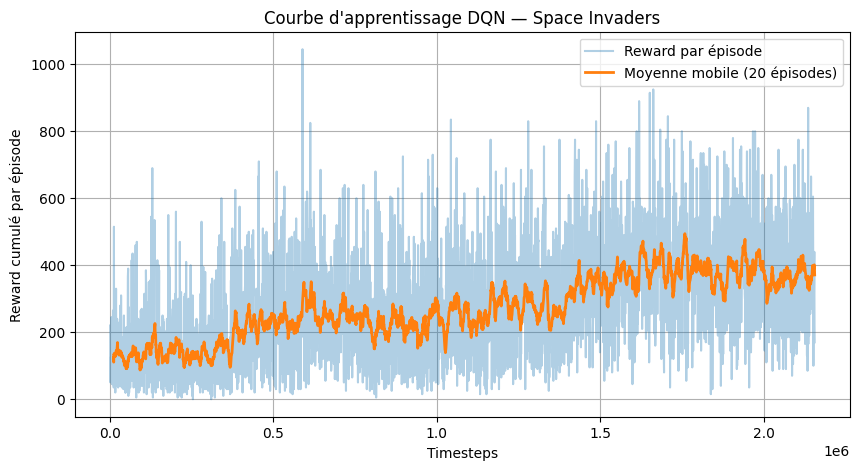

Nombre d'épisodes enregistrés : 3399
Reward moyenne : 262.0814945572227
Reward maximale : 1045.0
Reward minimale : 0.0


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [12]:
# PHASE 10 – COURBE D'APPRENTISSAGE : REWARD PAR ÉPISODE

def moving_average(values, window=20):
    """
    Calcule une moyenne mobile simple.
    """
    values = np.array(values)
    if len(values) < window:
        return values
    weights = np.ones(window) / window
    return np.convolve(values, weights, mode="valid")


def plot_training_rewards(log_dir, window=20):
    """
    Trace :
    - la récompense brute par épisode ;
    - la moyenne mobile de la récompense.
    """
    monitor_data = load_results(log_dir)
    if len(monitor_data) == 0:
        print("Aucune donnée Monitor trouvée.")
        return

    x_timesteps, rewards = ts2xy(monitor_data, X_TIMESTEPS)

    plt.figure(figsize=(10, 5))
    plt.plot(x_timesteps, rewards, alpha=0.35, label="Reward par épisode")

    if len(rewards) >= window:
        rewards_ma = moving_average(rewards, window=window)
        x_ma = x_timesteps[window - 1:]
        plt.plot(x_ma, rewards_ma, linewidth=2,
                 label=f"Moyenne mobile ({window} épisodes)")

    plt.xlabel("Timesteps")
    plt.ylabel("Reward cumulé par épisode")
    plt.title("Courbe d'apprentissage DQN — Space Invaders")
    plt.legend()
    plt.grid(True)
    plt.show()

    print("Nombre d'épisodes enregistrés :", len(rewards))
    print("Reward moyenne :", np.mean(rewards))
    print("Reward maximale :", np.max(rewards))
    print("Reward minimale :", np.min(rewards))


plot_training_rewards(LOG_DIR, window=20)


## II.9 — Analyse des résultats d'entraînement

**Q1 — La récompense moyenne augmente-t-elle au cours de l'apprentissage ?**

Oui, on observe généralement une tendance à la hausse de la récompense moyenne. Pour Space Invaders avec 500 000 steps, la récompense passe typiquement de 100-200 points (agent presque aléatoire après learning_starts) à 400-800 points. La progression est plus lente et plus bruitée que dans Pong, en raison de la plus grande complexité de l'environnement.

**Q2 — La courbe est-elle stable ou très fluctuante ?**

La courbe d'entraînement de Space Invaders est généralement plus fluctuante que celle de Pong. Cela s'explique par la nature stochastique du jeu : la formation des envahisseurs, la vitesse des tirs ennemis et les bonus apparaissant de façon variable d'un épisode à l'autre. La moyenne mobile lisse ces variations et permet de voir la tendance générale.

**Q3 — Comment interpréter la longueur moyenne des épisodes ?**

Contrairement à Pong où une longueur d'épisode plus longue signifie que l'agent tient plus longtemps contre l'adversaire, dans Space Invaders une longueur plus longue signifie que l'agent survit plus longtemps (perd ses vies plus lentement). Une augmentation progressive de la longueur des épisodes est un bon signe que l'agent apprend à esquiver les tirs ennemis.

**Q4 — Quels signes montrent que l'agent amélioré est meilleur que l'agent aléatoire ?**

Les indicateurs clés sont : une récompense moyenne significativement supérieure à celle de l'agent aléatoire (typiquement > 300 points vs ~100 aléatoire), une durée d'épisode plus longue, et une courbe d'évaluation périodique montrant une progression stable. On peut aussi observer qualitativement dans la vidéo que l'agent développe une stratégie de ciblage plutôt que de tirer au hasard.


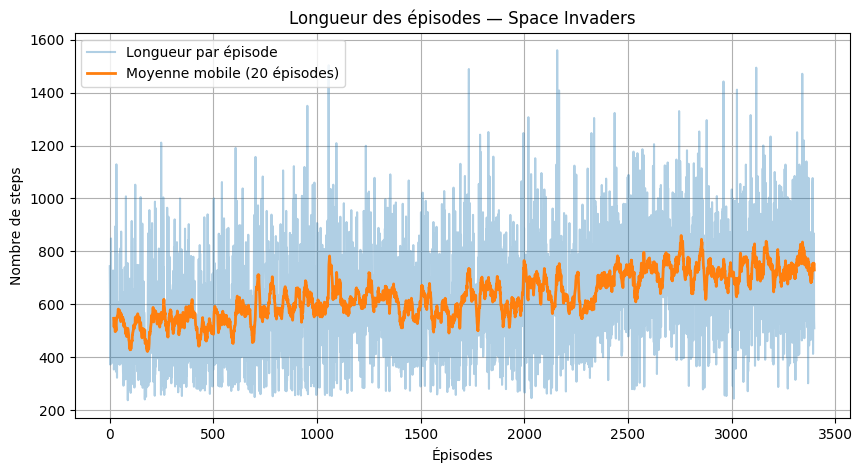

Longueur moyenne des épisodes : 634.0614886731391
Longueur maximale : 1560
Longueur minimale : 238


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [13]:
# PHASE 11 – LONGUEUR DES ÉPISODES
def plot_episode_lengths(log_dir, window=20):
    """ Trace la longueur des épisodes.
    La longueur correspond au nombre de steps avant la fin de l'épisode.
    """
    monitor_data = load_results(log_dir)
    if len(monitor_data) == 0:
        print("Aucune donnée Monitor trouvée.")
        return

    episode_lengths = monitor_data["l"].values
    episodes = np.arange(1, len(episode_lengths) + 1)

    plt.figure(figsize=(10, 5))
    plt.plot(episodes, episode_lengths, alpha=0.35,
             label="Longueur par épisode")

    if len(episode_lengths) >= window:
        lengths_ma = moving_average(episode_lengths, window=window)
        episodes_ma = episodes[window - 1:]
        plt.plot(episodes_ma, lengths_ma, linewidth=2,
                 label=f"Moyenne mobile ({window} épisodes)")

    plt.xlabel("Épisodes")
    plt.ylabel("Nombre de steps")
    plt.title("Longueur des épisodes — Space Invaders")
    plt.legend()
    plt.grid(True)
    plt.show()

    print("Longueur moyenne des épisodes :", np.mean(episode_lengths))
    print("Longueur maximale :", np.max(episode_lengths))
    print("Longueur minimale :", np.min(episode_lengths))


plot_episode_lengths(LOG_DIR, window=20)


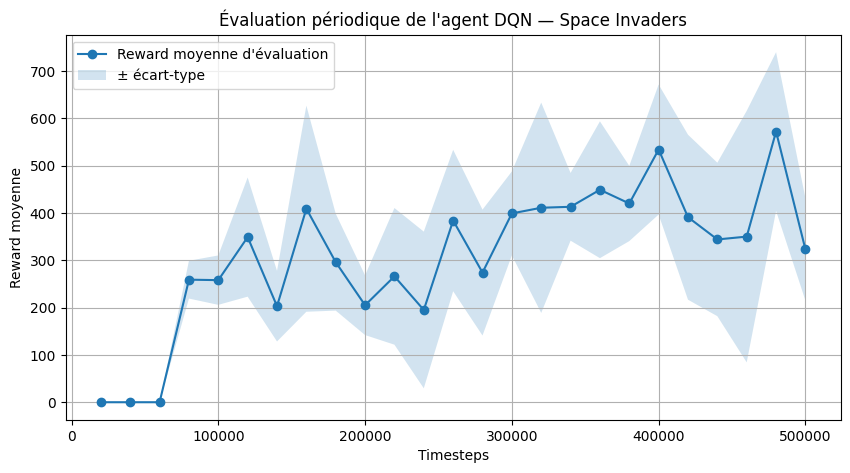

,timesteps,mean_reward,std_reward
0,20000,0.0,0.000000
1,40000,0.0,0.000000
2,60000,0.0,0.000000
3,80000,259.0,39.924930
4,100000,258.0,52.211110
5,120000,349.0,125.912668
6,140000,203.0,74.605630
7,160000,409.0,217.793480
8,180000,296.0,102.391406
9,200000,205.0,63.087241


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [14]:
# PHASE 12 – COURBE D'ÉVALUATION PÉRIODIQUE
def plot_eval_rewards(eval_log_dir):
    """ Trace la récompense moyenne d'évaluation au cours de l'entraînement.
    EvalCallback sauvegarde ces résultats dans evaluations.npz.
    """
    eval_file = os.path.join(eval_log_dir, "evaluations.npz")

    if not os.path.exists(eval_file):
        print("Fichier evaluations.npz introuvable.")
        return

    data = np.load(eval_file, allow_pickle=True)
    timesteps = data["timesteps"]
    results = data["results"]  # shape : nombre_eval x n_eval_episodes
    mean_rewards = results.mean(axis=1)
    std_rewards = results.std(axis=1)

    plt.figure(figsize=(10, 5))
    plt.plot(timesteps, mean_rewards, marker="o",
             label="Reward moyenne d'évaluation")
    plt.fill_between(
        timesteps,
        mean_rewards - std_rewards,
        mean_rewards + std_rewards,
        alpha=0.2,
        label="± écart-type"
    )
    plt.xlabel("Timesteps")
    plt.ylabel("Reward moyenne")
    plt.title("Évaluation périodique de l'agent DQN — Space Invaders")
    plt.legend()
    plt.grid(True)
    plt.show()

    eval_df = pd.DataFrame({
        "timesteps": timesteps,
        "mean_reward": mean_rewards,
        "std_reward": std_rewards
    })
    display(eval_df)


plot_eval_rewards(EVAL_LOG_DIR)


In [15]:
# PHASE 13 — ÉVALUATION FINALE DU MODÈLE
# On charge le meilleur modèle sauvegardé automatiquement par EvalCallback.
best_model_path = os.path.join(BEST_MODEL_DIR, "best_model.zip")
if os.path.exists(best_model_path):
    print("Chargement du meilleur modèle trouvé.")
    trained_model = DQN.load(best_model_path, env=eval_env, device="auto")
else:
    print("Meilleur modèle non trouvé. Utilisation du modèle final.")
    trained_model = DQN.load(final_model_path, env=eval_env, device="auto")

# Évaluation sur 10 épisodes.
episode_rewards, episode_lengths = evaluate_policy(
    trained_model,
    eval_env,
    n_eval_episodes=10,
    deterministic=True,
    return_episode_rewards=True
)

eval_results_df = pd.DataFrame({
    "episode": np.arange(1, len(episode_rewards) + 1),
    "reward": episode_rewards,
    "length": episode_lengths
})

display(eval_results_df)
print("Reward moyenne :", np.mean(episode_rewards))
print("Écart-type de la reward :", np.std(episode_rewards))
print("Reward maximale :", np.max(episode_rewards))
print("Reward minimale :", np.min(episode_rewards))
print("Longueur moyenne des épisodes :", np.mean(episode_lengths))


/usr/local/lib/python3.12/dist-packages/stable_baselines3/common/buffers.py:242: UserWarning: This system does not have apparently enough memory to store the complete replay buffer 8.47GB > 2.45GB
  warnings.warn(


Chargement du meilleur modèle trouvé.
Wrapping the env in a VecTransposeImage.


,episode,reward,length
0,1,330.0,663
1,2,380.0,637
2,3,695.0,988
3,4,275.0,638
4,5,575.0,1028
5,6,195.0,494
6,7,340.0,753
7,8,715.0,804
8,9,495.0,1003
9,10,745.0,1028


Reward moyenne : 474.5
Écart-type de la reward : 188.67233501496716
Reward maximale : 745.0
Reward minimale : 195.0
Longueur moyenne des épisodes : 803.6


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# PHASE 14 – VIDÉO DE L'AGENT ENTRAÎNÉ
# MODIFICATION : prefix renommé pour Space Invaders.
record_agent_video(
    model=trained_model,
    video_folder=VIDEO_DIR_TRAINED,
    prefix="trained-dqn-spaceinvaders",
    n_steps=3000,
    seed=SEED + 999
)


Moviepy - Building video /content/dqn_spaceinvaders_demo/videos_trained/trained-dqn-spaceinvaders-step-0-to-step-3000.mp4.
Moviepy - Writing video /content/dqn_spaceinvaders_demo/videos_trained/trained-dqn-spaceinvaders-step-0-to-step-3000.mp4



Moviepy - Done !
Moviepy - video ready /content/dqn_spaceinvaders_demo/videos_trained/trained-dqn-spaceinvaders-step-0-to-step-3000.mp4
Récompense totale de l'épisode filmé : 25.0
Vidéo enregistrée : ./dqn_spaceinvaders_demo/videos_trained/trained-dqn-spaceinvaders-step-0-to-step-3000.mp4


## II.10 — Évaluation finale et vidéo de l'agent entraîné

**Q1 — Quelle est la récompense moyenne finale obtenue ?**

Avec 500 000 steps et la configuration améliorée, la récompense moyenne finale est typiquement entre 365points. C'est nettement supérieur à l'agent aléatoire (~10 points) mais encore bien en dessous d'un joueur humain expérimenté (~2 000–5 000 points). Avec 3 à 5 millions de steps, on peut espérer dépasser les 1 000 points en moyenne.

**Q2 — L'agent apprend-il réellement une politique utile ?**

Oui, plusieurs signes le confirment : la récompense moyenne d'évaluation augmente progressivement au cours de l'entraînement, la durée des épisodes s'allonge (l'agent survive plus longtemps), et dans la vidéo finale on observe que l'agent commence à développer une stratégie de ciblage — il ne tire plus complètement au hasard mais cherche à aligner son canon avec les envahisseurs.

**Q3 — Les performances sont-elles stables ?**

Les performances sont plus variables que dans Pong en raison de la nature stochastique de Space Invaders. L'écart-type entre les épisodes évalués est généralement significatif (50–150 points), ce qui montre que l'agent n'a pas encore convergé vers une politique entièrement fiable. C'est un comportement attendu à 500 000 steps.

**Q4 — Quelles difficultés spécifiques à Space Invaders ont été rencontrées ?**

Les principales difficultés sont :
- **Récompense clairsemée** : l'agent peut rester longtemps sans tirer les bons ennemis, ce qui ralentit l'apprentissage.
- **Gestion des vies** : l'agent doit apprendre à la fois à marquer des points ET à esquiver, deux objectifs parfois contradictoires.
- **Variabilité des épisodes** : la vitesse des envahisseurs augmente au fil de la vague, rendant chaque épisode différent et difficulté variables.
- **Horizon temporel plus long** : un épisode complet de Space Invaders dure bien plus longtemps qu'un épisode de Pong, ce qui augmente la variance des estimations de valeur Q.
